# How has Netflix's catalogue strategy changed since 2015?

**Business question.** If you were advising a competing streamer, what has Netflix been prioritising in what it
adds to its catalogue: movies or TV, which countries, which genres and themes, new releases or back catalogue,
which audiences? And can the catalogue power a "because you watched" feature without any viewing data?

**Data.** `netflix_titles.csv` (Kaggle, Shivam Bansal): 8,807 titles available on Netflix in 2021, with the date
each was added (up to 25 September 2021). All logic lives in the tested `netflix_analytics` package (`src/`).

**Key caveat: a snapshot, not a history.** Titles added and later removed are missing, so earlier years are
under-counted, especially licensed content, which expires. Every trend describes titles that survived to 2021.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from netflix_analytics import data, recommend, topics, trends

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#9a9993', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 13, 'font.size': 10})
pd.set_option('display.precision', 3)

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=150, bbox_inches='tight'); plt.show()

## 0. Data quality

In [2]:
df, report = data.load_titles('netflix_titles.csv')
recent = data.window(df, 2015, 2021)
months_2021 = recent.loc[recent['year_added'] == 2021, 'date_added'].dt.month.max()
print(f"{report['titles']:,} titles; last addition {report['last_date_added']}; 2021 covers {months_2021} months")
print(f"Unparseable date_added (excluded from time trends): {len(report['unparsed_dates'])}")
print(f"Duration found in the rating column (moved back): {report['rating_holds_duration']['title'].tolist()}")
print(f"TV shows whose release_year is after the year they were added: {len(report['tv_release_year_after_added'])}")
report['tv_release_year_after_added'].head()

8,807 titles; last addition 2021-09-25; 2021 covers 9 months
Unparseable date_added (excluded from time trends): 10
Duration found in the rating column (moved back): ['Louis C.K. 2017', 'Louis C.K.: Hilarious', 'Louis C.K.: Live at the Comedy Store']
TV shows whose release_year is after the year they were added: 12


,title,release_year,year_added
0,Hilda,2021,2020
1,Polly Pocket,2021,2020
2,Love Is Blind,2021,2020
3,Fuller House,2020,2019
4,Maradona in Mexico,2020,2019


For TV shows, `release_year` is the year of the **latest season**, not the first: Sense8 arrived in 2016 and
ended in 2018. So "years between release and arriving on Netflix" is only meaningful for movies, and section 4
uses movies only.

## 1. How fast is the catalogue growing, and is it shifting to TV?

In [3]:
by_type = pd.crosstab(recent['year_added'], recent['type'])
by_type['total'] = by_type.sum(axis=1)
by_type['total_annualised'] = by_type['total'].astype(float)
by_type.loc[2021, 'total_annualised'] = round(by_type.loc[2021, 'total'] * 12 / months_2021)
tv = trends.share_by_year(recent, 'is_tv')
by_type.join(tv.round(1))

,Movie,TV Show,total,total_annualised,share_%,ci_low_%,ci_high_%,n
year_added,,,,,,,,
2015,56,26,82,82.0,31.7,22.6,42.4,82
2016,253,176,429,429.0,41.0,36.5,45.7,429
2017,839,349,1188,1188.0,29.4,26.9,32.0,1188
2018,1237,412,1649,1649.0,25.0,23.0,27.1,1649
2019,1424,592,2016,2016.0,29.4,27.4,31.4,2016
2020,1284,595,1879,1879.0,31.7,29.6,33.8,1879
2021,993,505,1498,1997.0,33.7,31.4,36.1,1498


TV share 2018-2021: odds rise 1.146x per year (95% CI 1.092-1.202), p = 2.5e-08


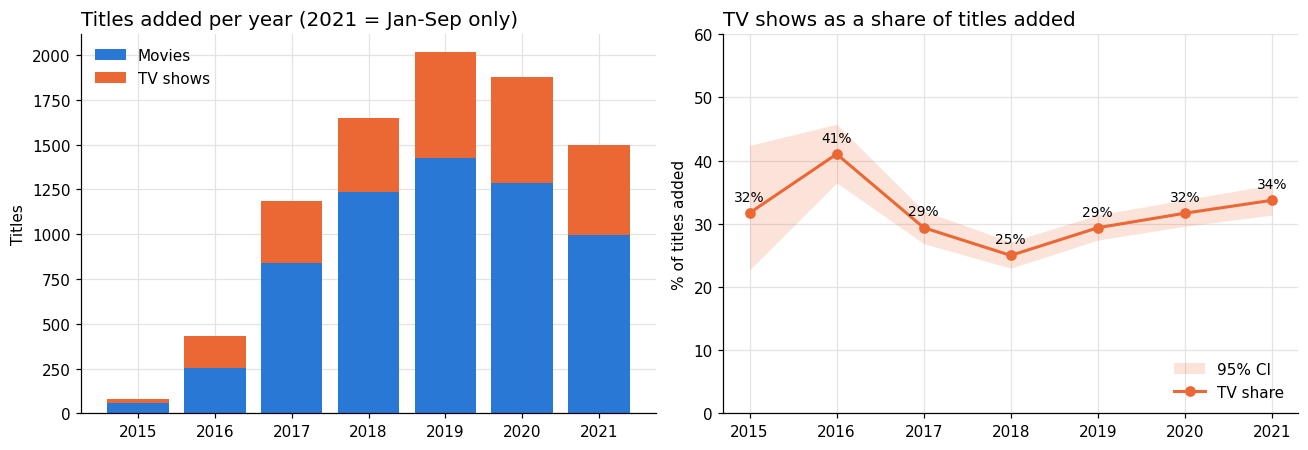

In [4]:
tv_trend = trends.trend_test(recent, 'is_tv', 2018, 2021)
print(f"TV share 2018-2021: odds rise {tv_trend['odds_ratio_per_year']:.3f}x per year "
      f"(95% CI {tv_trend['ci_low']:.3f}-{tv_trend['ci_high']:.3f}), p = {tv_trend['p_value']:.1e}")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2))
years = by_type.index.astype(int)
a.bar(years, by_type['Movie'], color=BLUE, label='Movies')
a.bar(years, by_type['TV Show'], bottom=by_type['Movie'], color=ORANGE, label='TV shows')
a.set_title('Titles added per year (2021 = Jan-Sep only)'); a.set_ylabel('Titles'); a.legend(frameon=False)
b.fill_between(tv.index.astype(int), tv['ci_low_%'], tv['ci_high_%'], color=ORANGE, alpha=0.18, linewidth=0, label='95% CI')
b.plot(tv.index.astype(int), tv['share_%'], color=ORANGE, lw=2, marker='o', label='TV share')
for x, v in zip(tv.index.astype(int), tv['share_%'], strict=True):
    b.annotate(f'{v:.0f}%', (x, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
b.set_title('TV shows as a share of titles added'); b.set_ylabel('% of titles added'); b.set_ylim(0, 60)
b.legend(frameon=False, loc='lower right')
save(fig, '01_growth_and_tv_share.png')

The 2015 and 2016 shares rest on 82 and 429 titles, hence the wide intervals; the 2018-2021 rise is on 400+
shows a year and is highly significant.

## 2. Which countries is Netflix adding content from?

Every listed country is counted, so co-productions aren't undercounted.

In [5]:
countries = data.explode_list(recent, 'countries', 'country')
country_share = pd.crosstab(countries['year_added'], countries['country'], normalize='index') * 100
country_share.index = country_share.index.astype(int)
top = countries['country'].value_counts().head(6).index
countries['is_india'] = (countries['country'] == 'India').astype(int)
rise, fall = trends.compare_years(countries, 'is_india', 2016, 2018), trends.compare_years(countries, 'is_india', 2018, 2021)
print(f"India: {rise['share_from_%']:.1f}% (2016) -> {rise['share_to_%']:.1f}% (2018), p = {rise['p_value']:.1e}; "
      f"-> {fall['share_to_%']:.1f}% (2021), p = {fall['p_value']:.1e}")
print(f"United States: {country_share.loc[2018, 'United States']:.1f}% (2018) -> {country_share.loc[2021, 'United States']:.1f}% (2021)")
country_share[top].loc[2016:].round(1)

India: 2.4% (2016) -> 18.2% (2018), p = 1.3e-19; -> 7.1% (2021), p = 1.4e-20
United States: 31.3% (2018) -> 42.7% (2021)


country,United States,India,United Kingdom,Canada,France,Japan
year_added,,,,,,
2016,37.7,2.4,10.0,5.6,5.4,5.4
2017,32.8,11.5,9.5,5.0,3.8,2.6
2018,31.3,18.2,7.7,4.2,3.3,2.3
2019,37.8,9.6,8.4,3.7,3.5,3.3
2020,37.2,8.9,6.6,4.9,4.4,3.5
2021,42.7,7.1,8.2,4.0,4.1,3.6


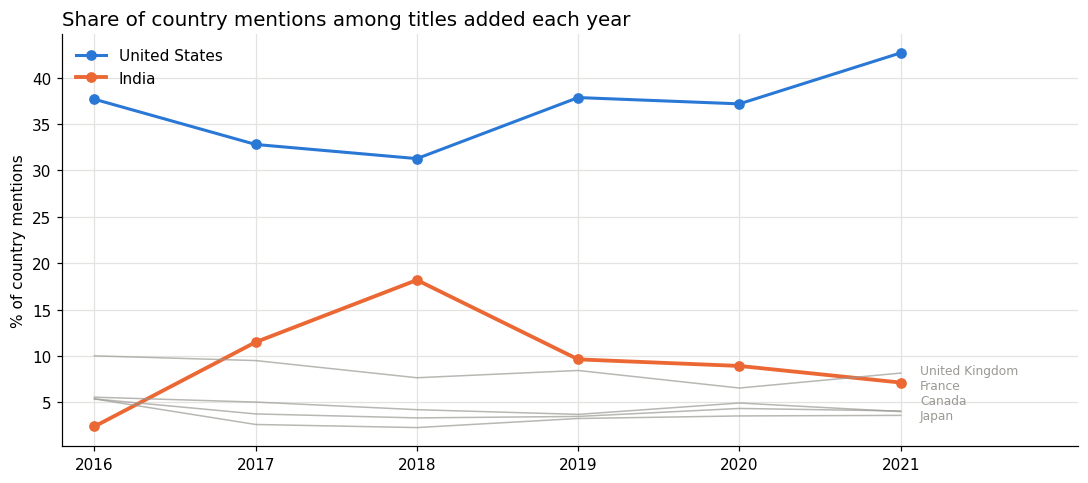

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
cs = country_share.loc[2016:]
ax.plot(cs.index, cs['United States'], color=BLUE, lw=2, marker='o', label='United States')
ax.plot(cs.index, cs['India'], color=ORANGE, lw=2.5, marker='o', label='India')
others = [c for c in top if c not in ('United States', 'India')]
for name in others:
    ax.plot(cs.index, cs[name], color=GREY, lw=1, alpha=0.7)
label_y, last = {}, None
for name in sorted(others, key=lambda n: cs[n].iloc[-1]):
    y = cs[name].iloc[-1] if last is None else max(cs[name].iloc[-1], last + 1.6)
    label_y[name] = last = y
for name, y in label_y.items():
    ax.annotate(name, (cs.index[-1], cs[name].iloc[-1]), xytext=(cs.index[-1] + 0.12, y), textcoords='data',
                fontsize=8, color=GREY, va='center')
ax.set_title('Share of country mentions among titles added each year'); ax.set_ylabel('% of country mentions')
ax.legend(frameon=False, loc='upper left'); ax.set_xlim(2015.8, 2022.1); ax.set_xticks(cs.index)
save(fig, '02_country_mix.png')

## 3. Which genres are gaining and losing share?

Two-year windows (2016-17 vs 2020-21) smooth single-year noise.

In [7]:
genres = data.explode_list(recent, 'genres', 'genre')
change = trends.share_change(genres, 'genre', before=(2016, 2017), after=(2020, 2021))
movers = pd.concat([change.head(5), change.tail(5)])
movers.round(2).rename('share change, percentage points')

genre
Documentaries              -5.00
Stand-Up Comedy            -2.65
International TV Shows     -2.13
Romantic TV Shows          -1.88
British TV Shows           -1.05
Children & Family Movies    1.24
Action & Adventure          2.12
Romantic Movies             2.20
Dramas                      3.29
Comedies                    3.36
Name: share change, percentage points, dtype: float64

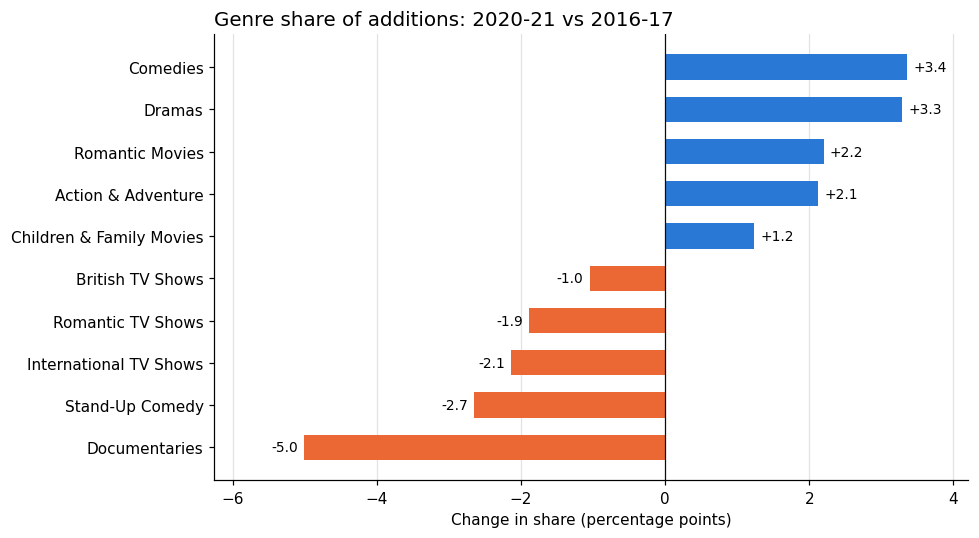

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(movers.index, movers.values, color=[ORANGE if v < 0 else BLUE for v in movers.values], height=0.6)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlim(movers.min() * 1.25, movers.max() * 1.25)
for y, v in enumerate(movers.values):
    ax.annotate(f'{v:+.1f}', (v, y), xytext=(4 if v > 0 else -4, 0), textcoords='offset points',
                ha='left' if v > 0 else 'right', va='center', fontsize=9)
ax.set_title('Genre share of additions: 2020-21 vs 2016-17'); ax.set_xlabel('Change in share (percentage points)')
ax.grid(axis='y', visible=False)
save(fig, '03_genre_movers.png')

## 4. New releases or back catalogue? (movies only)

A movie is *fresh* if it arrived on Netflix the year it was released or the year after.

In [9]:
movies = recent[recent['type'] == 'Movie'].assign(fresh=lambda d: (d['content_age'] <= 1).astype(int))
fresh = trends.share_by_year(movies, 'fresh')
fresh_trend = trends.trend_test(movies, 'fresh', 2016, 2021)
print(f"Fresh share of movies: {fresh.loc[2016, 'share_%']:.0f}% (2016) -> {fresh.loc[2021, 'share_%']:.0f}% (2021); "
      f"odds x{fresh_trend['odds_ratio_per_year']:.2f} per year, p = {fresh_trend['p_value']:.1e}")
fresh.round(1)

Fresh share of movies: 75% (2016) -> 40% (2021); odds x0.80 per year, p = 1.1e-31


,share_%,ci_low_%,ci_high_%,n
year_added,,,,
2015,89.3,78.5,95.0,56
2016,75.5,69.8,80.4,253
2017,62.8,59.5,66.0,839
2018,49.0,46.2,51.8,1237
2019,45.9,43.3,48.5,1424
2020,46.0,43.3,48.8,1284
2021,40.0,37.0,43.1,993


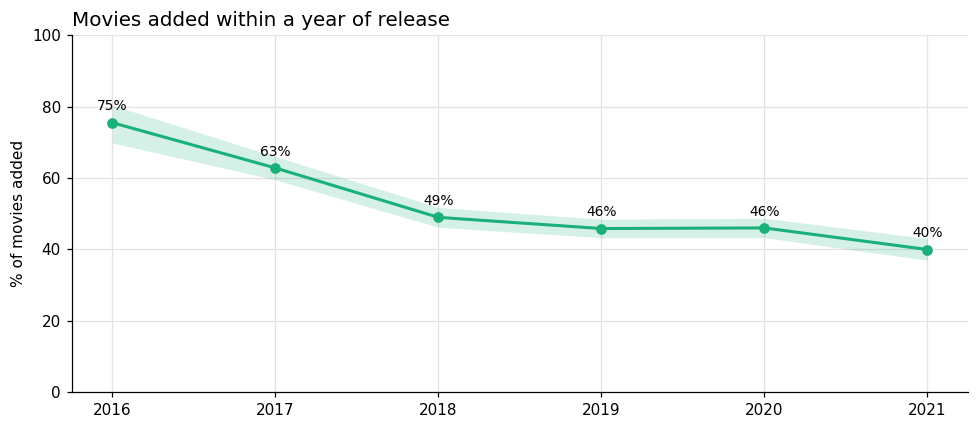

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
f = fresh.loc[2016:]
ax.fill_between(f.index.astype(int), f['ci_low_%'], f['ci_high_%'], color=AQUA, alpha=0.18, linewidth=0)
ax.plot(f.index.astype(int), f['share_%'], color=AQUA, lw=2, marker='o')
for x, v in zip(f.index.astype(int), f['share_%'], strict=True):
    ax.annotate(f'{v:.0f}%', (x, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
ax.set_title('Movies added within a year of release'); ax.set_ylabel('% of movies added'); ax.set_ylim(0, 100)
save(fig, '04_fresh_vs_catalogue.png')

The snapshot caveat bites hardest here: licensed back-catalogue movies from 2016-17 have had more time to
expire and vanish from the data, which makes early years look *fresher* than they were. The decline is real but
its size is likely overstated.

## 5. Who is the catalogue for?

In [11]:
kids, mature = trends.share_by_year(recent, 'is_kids'), trends.share_by_year(recent, 'is_mature')
kids_trend = trends.trend_test(recent, 'is_kids', 2018, 2021)
print(f"Kids share: {kids.loc[2018, 'share_%']:.1f}% (2018) -> {kids.loc[2021, 'share_%']:.1f}% (2021), "
      f"p = {kids_trend['p_value']:.1e}")
pd.DataFrame({'kids_%': kids['share_%'], 'mature_%': mature['share_%']}).loc[2016:].round(1)

Kids share: 10.1% (2018) -> 16.7% (2021), p = 6.6e-11


,kids_%,mature_%
year_added,,
2016,15.9,41.3
2017,10.7,43.2
2018,10.1,47.2
2019,11.8,46.9
2020,16.7,45.7
2021,16.7,45.3


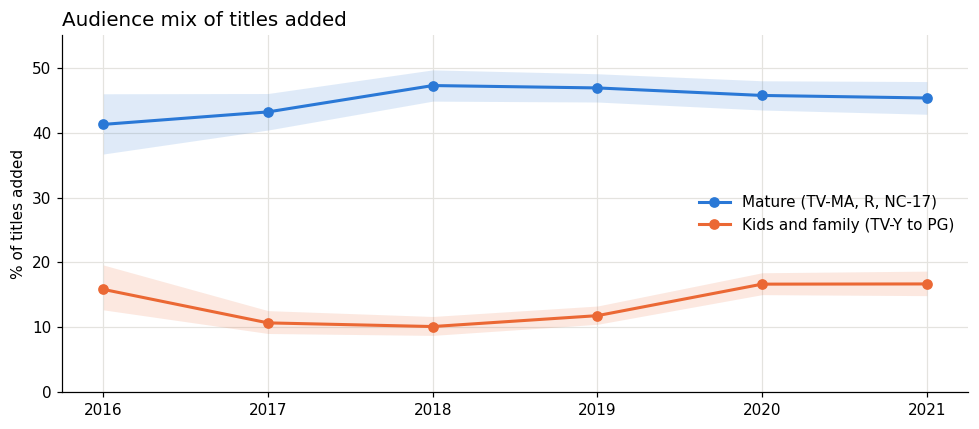

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
for s, color, label in [(mature, BLUE, 'Mature (TV-MA, R, NC-17)'), (kids, ORANGE, 'Kids and family (TV-Y to PG)')]:
    s = s.loc[2016:]
    ax.fill_between(s.index.astype(int), s['ci_low_%'], s['ci_high_%'], color=color, alpha=0.15, linewidth=0)
    ax.plot(s.index.astype(int), s['share_%'], color=color, lw=2, marker='o', label=label)
ax.set_title('Audience mix of titles added'); ax.set_ylabel('% of titles added'); ax.set_ylim(0, 55)
ax.legend(frameon=False, loc='center right')
save(fig, '05_audience_mix.png')

## 6. What are the stories about? Topic modelling of descriptions

Genres are coarse labels. The descriptions say what titles are actually *about*. TF-IDF + NMF finds themes as
weighted word lists. The number of themes is chosen by **stability**: refit from five random starts and check the
same themes come back (1.0 = identical every time).

In [13]:
stability = topics.topic_stability(df['description'], ks=[8, 12, 16], seeds=5)
stability.round(3)

8     0.825
12    0.872
16    0.873
Name: stability, dtype: float64

12 themes are as stable as 16 and clearly more stable than 8, so 12 is the most detailed split the data
supports without over-splitting.

In [14]:
model = topics.fit_topics(df['description'], k=12)
labels = model.labels(3)
pd.DataFrame({'theme (top 3 words)': labels, 'top words': [', '.join(t) for t in model.top_terms(8)]})

,theme (top 3 words),top words
0,documentary / series / follows,"documentary, series, follows, lives, story, ba..."
1,young / man / woman,"young, man, woman, marriage, loves, falls, fin..."
2,school / high / student,"school, high, student, students, teen, teacher..."
3,life / career / real,"life, career, real, changing, turned, upside, ..."
4,new / york / city,"new, york, city, home, finds, couple, moves, soon"
5,family / home / returns,"family, home, returns, years, wealthy, busines..."
6,love / falls / fall,"love, falls, fall, romance, true, girl, triang..."
7,old / year / home,"old, year, home, 11, 10, girl, boy, friend"
8,stand / special / comedy,"stand, special, comedy, comedian, takes, stage..."
9,world / war / ii,"world, war, ii, save, way, evil, fight, power"


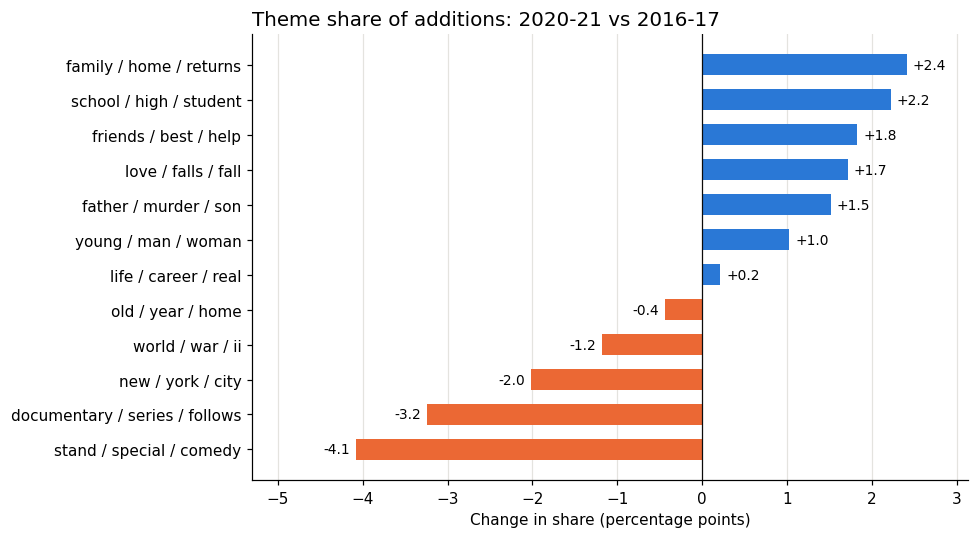

theme
stand / special / comedy         -4.08
documentary / series / follows   -3.24
new / york / city                -2.02
world / war / ii                 -1.18
old / year / home                -0.43
life / career / real              0.22
young / man / woman               1.03
father / murder / son             1.52
love / falls / fall               1.72
friends / best / help             1.83
school / high / student           2.23
family / home / returns           2.41
dtype: float64

In [15]:
df['theme'] = pd.Series(model.dominant_topic(), index=df.index).map(dict(enumerate(labels)))
theme_titles = data.window(df, 2016, 2021).dropna(subset=['theme'])
theme_change = trends.share_change(theme_titles, 'theme', before=(2016, 2017), after=(2020, 2021))
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(theme_change.index, theme_change.values, color=[ORANGE if v < 0 else BLUE for v in theme_change.values], height=0.6)
ax.axvline(0, color=INK, lw=0.8)
for y, v in enumerate(theme_change.values):
    ax.annotate(f'{v:+.1f}', (v, y), xytext=(4 if v > 0 else -4, 0), textcoords='offset points',
                ha='left' if v > 0 else 'right', va='center', fontsize=9)
ax.set_xlim(theme_change.min() * 1.3, theme_change.max() * 1.3)
ax.set_title('Theme share of additions: 2020-21 vs 2016-17'); ax.set_xlabel('Change in share (percentage points)')
ax.grid(axis='y', visible=False)
save(fig, '06_theme_movers.png')
theme_change.round(2)

## 7. "Because you watched...": a content-based recommender

Recommendations mix description (50%), genres (30%), director and cast (10% each) and stay within type (movies
for movies, shows for shows).

In [16]:
recommender = recommend.ContentRecommender().fit(df)
recommender.recommend('Stranger Things', k=5)

,title,type,listed_in,release_year,similarity
0,Chilling Adventures of Sabrina,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",2020,0.300
1,Nightflyers,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",2018,0.300
2,Helix,TV Show,"TV Horror, TV Mysteries, TV Sci-Fi & Fantasy",2015,0.300
3,Anjaan: Special Crimes Unit,TV Show,"International TV Shows, TV Horror, TV Mysteries",2018,0.265
4,The Haunting of Hill House,TV Show,"TV Dramas, TV Horror, TV Mysteries",2018,0.263


In [17]:
recommender.recommend('The Irishman', k=5)

,title,type,listed_in,release_year,similarity
0,Gangs of New York,Movie,Dramas,2002,0.421
1,Catch Me If You Can,Movie,Dramas,2002,0.378
2,Freedom Writers,Movie,Dramas,2007,0.345
3,War Horse,Movie,Dramas,2011,0.343
4,Cut Throat City,Movie,Dramas,2020,0.338


**Does it work?** Without viewing data, a fair offline test: build recommendations from **descriptions only**,
then check how often they share a genre with the title asked about. Genres aren't in the input, so agreement is
earned. The baseline is a random title **of the same type**, because genres are type-specific ("TV Dramas" vs
"Dramas") and matching movies with movies alone raises agreement a lot.

In [18]:
evaluation = recommend.genre_agreement_eval(df, k=10, n_queries=1500)
print(f"Top-10 description-only recommendations share a genre {evaluation['model_genre_agreement']:.1%} of the time, "
      f"vs {evaluation['random_same_type_agreement']:.1%} for random same-type titles: "
      f"+{evaluation['lift'] * 100:.1f} points (95% CI {evaluation['lift_ci_low'] * 100:.1f} to {evaluation['lift_ci_high'] * 100:.1f})")
print(f"For reference, a random title of any type shares a genre {evaluation['random_any_type_agreement']:.1%} of the time: "
      "comparing with that would overstate the model's lift.")

Top-10 description-only recommendations share a genre 63.4% of the time, vs 41.7% for random same-type titles: +21.8 points (95% CI 20.5 to 23.0)
For reference, a random title of any type shares a genre 23.6% of the time: comparing with that would overstate the model's lift.


## 8. Findings and recommendations

Among titles still on Netflix in 2021 (numbers printed above):

1. **Growth has levelled off.** Additions peaked in 2019; 2021 is on a similar annualised pace.
2. **A swing back to TV.** TV's share of additions has risen every year since its 2018 low, a highly significant trend.
3. **India was a short, sharp bet.** Its share of country mentions rose about sevenfold from 2016 to 2018, then fell
   by about 60% by 2021; both moves are far beyond chance. The US share rose over the same period.
4. **Comedies and dramas gained share; documentaries and stand-up lost the most**, and the description themes agree.
5. **More back-catalogue movies.** The share of movies added within a year of release fell sharply from 2016 to 2021
   (the snapshot effect likely exaggerates the size of the fall).
6. **Kids content is returning** from its 2018 low.
7. **The catalogue alone supports a useful recommender:** description-based recommendations agree on genre about
   22 points more often than random same-type picks.

**If I were advising a competing streamer:**
- **Compete on retention, not catalogue size.** With additions flat and TV rising, Netflix is optimising for series
  that keep subscribers; benchmark against TV hours, not title count.
- **Treat regional expansion as a multi-year commitment.** Netflix's India push reversed within three years.
- **Move on family content early;** Netflix is rebuilding its kids catalogue.
- **Ship a content-based recommender from day one.** It needs no viewing history (useful for new users and new
  titles) and can later be blended with collaborative filtering once viewing data exists.

**Limitations.** Snapshot data (removed titles are missing); counts of titles, not viewing hours; no cost or
audience data; recommender evaluated by a genre proxy, not user behaviour.